# Reconocimiento de comidas y verduras mediante CNN
## Pipeline integrador — Sesión 08

**Curso:** IS056B — Ingeniería del Conocimiento  
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas  
**Docente:** Msc. Jaime Antonio Huaytalla Pariona  
**Semestre:** 2026-II

### Objetivo
Desarrollar un sistema de clasificación multiclase de imágenes de comidas y verduras mediante redes neuronales convolucionales (CNN), siguiendo las 12 fases solicitadas en la práctica integradora.

**Importante:** este notebook conserva el dataset del proyecto original, organizado en carpetas `train`, `validation` y `test`. No utiliza PlantVillage, porque ese conjunto de datos corresponde a enfermedades de plantas y no al reconocimiento de comidas y verduras.

**Ejecución:** en Google Colab, ejecutar desde el inicio y en orden. La primera ejecución puede tardar según el tamaño del dataset y la GPU disponible.

## Fase 0. Configuración del entorno

In [1]:
import os, json, datetime, platform, random, pathlib, collections, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score, precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("GPU disponibles:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Fase 1. Definición del problema

| Pregunta | Respuesta del proyecto |
|---|---|
| ¿Qué problema resuelve? | Clasifica imágenes de comidas y verduras en la categoría correspondiente para apoyar su identificación automática. |
| Tipo de problema | Clasificación multiclase supervisada. |
| Métrica principal | Macro F1-score y accuracy. Accuracy muestra el acierto global; Macro F1 considera el rendimiento de todas las clases, incluso si están desbalanceadas. |
| Restricciones | Calidad y cantidad de imágenes, similitud visual entre categorías, capacidad de cómputo y tamaño del modelo para su despliegue. |
| Baseline | Clasificador mayoritario: siempre predice la clase más frecuente. Su accuracy equivale a la proporción de imágenes de esa clase. También se considera el azar como referencia secundaria (1/número de clases). |

El objetivo es superar el baseline y comprobar el rendimiento final con el conjunto de prueba, que no se utiliza durante el entrenamiento.

## Fase 2. Dataset y análisis exploratorio (EDA)

El dataset debe estar dividido en tres carpetas y cada una debe contener subcarpetas por clase:

```text
FoodDataset/
  train/
    clase_1/ imagenes...
    clase_2/ imagenes...
  validation/
    clase_1/ imagenes...
    clase_2/ imagenes...
  test/
    clase_1/ imagenes...
    clase_2/ imagenes...
```

Si el ZIP está en Google Drive, se descomprime una sola vez.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = '/content/drive/MyDrive/archive.zip'  # Cambiar si el ZIP tiene otro nombre o ubicación
DATA_ROOT = '/content/FoodDataset'

if not os.path.isdir(DATA_ROOT):
    if os.path.isfile(ZIP_PATH):
        import zipfile
        with zipfile.ZipFile(ZIP_PATH, 'r') as z:
            z.extractall(DATA_ROOT)
        print("Dataset descomprimido.")
    else:
        raise FileNotFoundError(
            f"No se encontró {ZIP_PATH}. Sube el ZIP a Drive o modifica ZIP_PATH."
        )

# Detectar automáticamente si el ZIP creó una carpeta intermedia.
def find_split_root(root):
    for current, dirs, files in os.walk(root):
        names = {d.lower() for d in dirs}
        if {'train', 'validation', 'test'}.issubset(names):
            return current
    return root

DATA_ROOT = find_split_root(DATA_ROOT)
train_dir = os.path.join(DATA_ROOT, 'train')
val_dir = os.path.join(DATA_ROOT, 'validation')
test_dir = os.path.join(DATA_ROOT, 'test')

for path in [train_dir, val_dir, test_dir]:
    if not os.path.isdir(path):
        raise FileNotFoundError(f"No existe la carpeta requerida: {path}")

print("Ruta del dataset:", DATA_ROOT)
print("Train:", train_dir)
print("Validation:", val_dir)
print("Test:", test_dir)

Mounted at /content/drive
Dataset descomprimido.
Ruta del dataset: /content/FoodDataset
Train: /content/FoodDataset/train
Validation: /content/FoodDataset/validation
Test: /content/FoodDataset/test


In [3]:
# Cargar los tres subconjuntos. Las etiquetas se representan como enteros.
train_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='int', shuffle=True, seed=SEED
)
val_raw = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='int', shuffle=False
)
test_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='int', shuffle=False
)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)

if val_raw.class_names != class_names or test_raw.class_names != class_names:
    raise ValueError("Las clases y su orden deben ser idénticos en train, validation y test.")

print("Número de clases:", NUM_CLASSES)
print("Clases:", class_names)

Found 3115 files belonging to 36 classes.
Found 351 files belonging to 36 classes.
Found 359 files belonging to 36 classes.
Número de clases: 36
Clases: ['apple', 'banana', 'beetroot', 'bell pepper', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli pepper', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'jalepeno', 'kiwi', 'lemon', 'lettuce', 'mango', 'onion', 'orange', 'paprika', 'pear', 'peas', 'pineapple', 'pomegranate', 'potato', 'raddish', 'soy beans', 'spinach', 'sweetcorn', 'sweetpotato', 'tomato', 'turnip', 'watermelon']


In [4]:
# Conteo real de imágenes por clase en cada subconjunto.
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}

def count_images_by_class(folder):
    counts = {}
    for class_name in sorted(os.listdir(folder)):
        class_path = os.path.join(folder, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = sum(
                1 for f in os.listdir(class_path)
                if pathlib.Path(f).suffix.lower() in IMG_EXTS
            )
    return counts

counts_train = count_images_by_class(train_dir)
counts_val = count_images_by_class(val_dir)
counts_test = count_images_by_class(test_dir)

eda_df = pd.DataFrame({
    'Clase': class_names,
    'Entrenamiento': [counts_train.get(c, 0) for c in class_names],
    'Validación': [counts_val.get(c, 0) for c in class_names],
    'Prueba': [counts_test.get(c, 0) for c in class_names]
})
eda_df['Total'] = eda_df[['Entrenamiento', 'Validación', 'Prueba']].sum(axis=1)
display(eda_df)
print("\nTotal de imágenes:", int(eda_df['Total'].sum()))
print("Clase mayoritaria:", eda_df.loc[eda_df['Total'].idxmax(), 'Clase'])
print("Clase minoritaria:", eda_df.loc[eda_df['Total'].idxmin(), 'Clase'])
print("Baseline mayoritario:", f"{eda_df['Total'].max()/eda_df['Total'].sum():.2%}")
print("Baseline aleatorio:", f"{1/NUM_CLASSES:.2%}")

,Clase,Entrenamiento,Validación,Prueba,Total
0,apple,68,10,10,88
1,banana,75,9,9,93
2,beetroot,88,10,10,108
3,bell pepper,90,9,10,109
4,cabbage,92,10,10,112
5,capsicum,89,10,10,109
6,carrot,82,9,10,101
7,cauliflower,79,10,10,99
8,chilli pepper,87,9,10,106
9,corn,87,10,10,107



Total de imágenes: 3825
Clase mayoritaria: peas
Clase minoritaria: apple
Baseline mayoritario: 3.14%
Baseline aleatorio: 2.78%


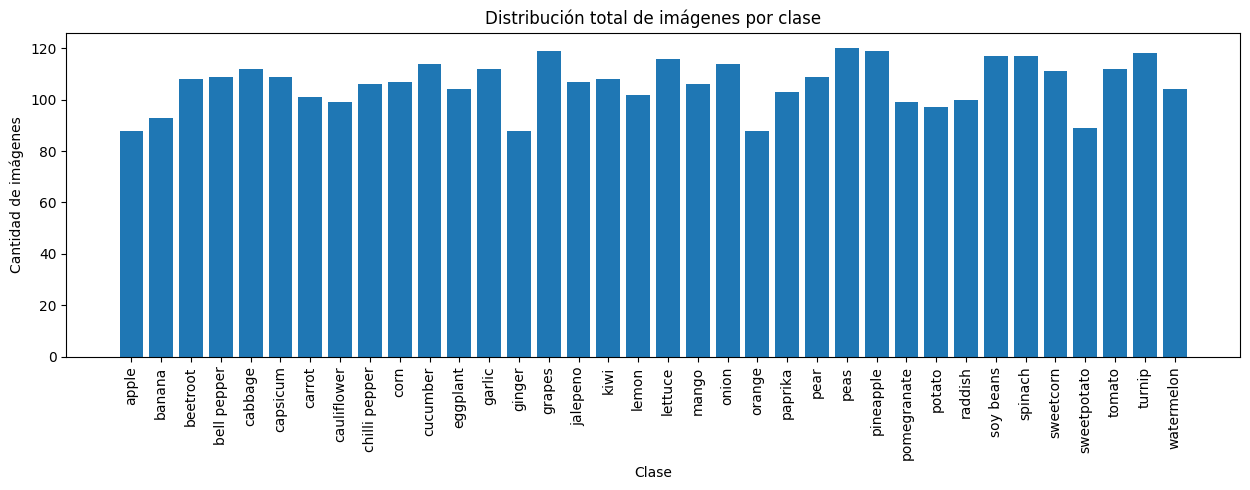

In [5]:
plt.figure(figsize=(max(12, NUM_CLASSES * 0.35), 5))
plt.bar(eda_df['Clase'], eda_df['Total'])
plt.title('Distribución total de imágenes por clase')
plt.xlabel('Clase')
plt.ylabel('Cantidad de imágenes')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [6]:
# Inspección de dimensiones y canales de una muestra.
widths, heights, channels = [], [], []
for class_name in class_names:
    folder = os.path.join(train_dir, class_name)
    for fname in os.listdir(folder)[:10]:
        path = os.path.join(folder, fname)
        try:
            with Image.open(path) as im:
                widths.append(im.width)
                heights.append(im.height)
                channels.append(len(im.getbands()))
        except Exception:
            pass

if widths:
    print(f"Ancho: min={min(widths)}, max={max(widths)}, promedio={np.mean(widths):.1f}")
    print(f"Alto: min={min(heights)}, max={max(heights)}, promedio={np.mean(heights):.1f}")
    print("Canales encontrados:", collections.Counter(channels))
else:
    print("No se pudieron inspeccionar imágenes de muestra.")

Ancho: min=208, max=5887, promedio=1156.3
Alto: min=208, max=5344, promedio=975.6
Canales encontrados: Counter({3: 341, 4: 18, 1: 1})


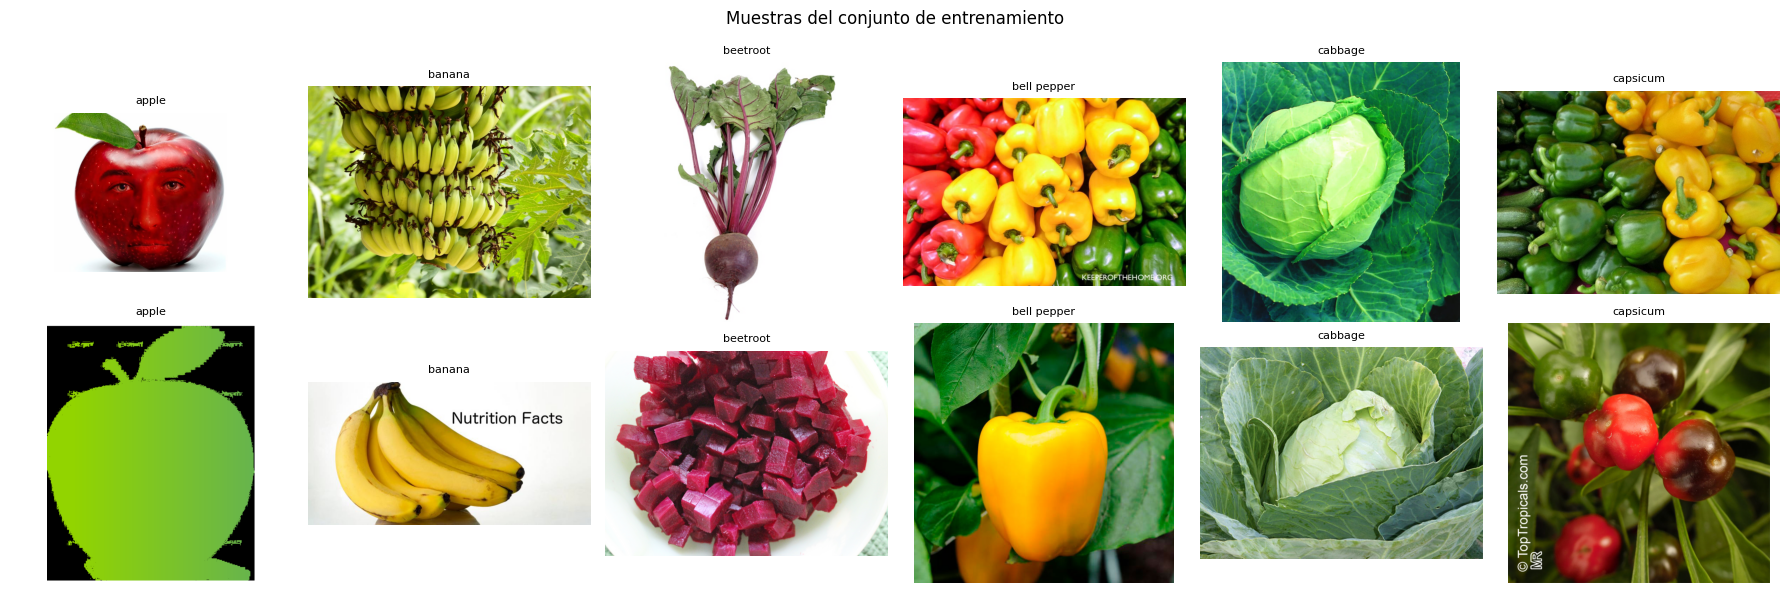

In [7]:
# Mostrar ejemplos de hasta seis clases.
n_show = min(6, NUM_CLASSES)
fig, axes = plt.subplots(2, n_show, figsize=(3*n_show, 6))
if n_show == 1:
    axes = np.array(axes).reshape(2, 1)

for col, class_name in enumerate(class_names[:n_show]):
    folder = os.path.join(train_dir, class_name)
    files = [f for f in os.listdir(folder) if pathlib.Path(f).suffix.lower() in IMG_EXTS][:2]
    for row in range(2):
        axes[row, col].axis('off')
        if row < len(files):
            with Image.open(os.path.join(folder, files[row])) as im:
                axes[row, col].imshow(im.convert('RGB'))
            axes[row, col].set_title(class_name, fontsize=8)
plt.suptitle('Muestras del conjunto de entrenamiento')
plt.tight_layout()
plt.show()

In [8]:
# Detectar imágenes corruptas sin detener el proceso.
def find_corrupted_images(directory):
    corrupted, total = [], 0
    for root, _, files in os.walk(directory):
        for fname in files:
            if pathlib.Path(fname).suffix.lower() not in IMG_EXTS:
                continue
            total += 1
            path = os.path.join(root, fname)
            try:
                with Image.open(path) as im:
                    im.verify()
            except Exception as exc:
                corrupted.append((path, str(exc)))
    return corrupted, total

for split_name, split_dir in [('train', train_dir), ('validation', val_dir), ('test', test_dir)]:
    bad, total = find_corrupted_images(split_dir)
    pct = (len(bad)/total*100) if total else 0
    print(f"{split_name}: {total} imágenes revisadas; {len(bad)} corruptas ({pct:.2f}%).")
    for path, error in bad[:3]:
        print("  -", path, "|", error)

train: 3115 imágenes revisadas; 0 corruptas (0.00%).
validation: 351 imágenes revisadas; 0 corruptas (0.00%).
test: 359 imágenes revisadas; 0 corruptas (0.00%).


## Fase 3. Preprocesamiento y aumento de datos

Las imágenes se normalizan de 0–255 a 0–1. El aumento de datos se aplica únicamente durante el entrenamiento; validación y prueba conservan las imágenes originales. Se utiliza `cache` y `prefetch` para mejorar el rendimiento.

In [9]:
normalization = tf.keras.layers.Rescaling(1./255, name='normalization')
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
], name='data_augmentation')

def prepare_train(images, labels):
    images = normalization(images)
    images = data_augmentation(images, training=True)
    return images, labels

def prepare_eval(images, labels):
    return normalization(images), labels

train_ds = train_raw.map(prepare_train, num_parallel_calls=AUTOTUNE)
val_ds = val_raw.map(prepare_eval, num_parallel_calls=AUTOTUNE)
test_ds = test_raw.map(prepare_eval, num_parallel_calls=AUTOTUNE)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

print("Pipelines listos.")

Pipelines listos.


## Fase 4. Diseño de tres modelos CNN

Se comparan tres arquitecturas: una CNN base, una CNN con conexiones residuales y una CNN optimizada con regularización. Las tres reciben imágenes normalizadas de 224 × 224 × 3 y producen probabilidades para todas las clases.

In [10]:
def conv_block(x, filters, pool=True):
    x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    if pool:
        x = tf.keras.layers.MaxPooling2D()(x)
    return x

def build_baseline(input_shape, num_classes):
    inputs = tf.keras.Input(shape=input_shape)
    x = conv_block(inputs, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.4)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_baseline')

def residual_block(x, filters, stride=1):
    shortcut = x
    y = tf.keras.layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False)(x)
    y = tf.keras.layers.BatchNormalization()(y)
    y = tf.keras.layers.Activation('relu')(y)
    y = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(y)
    y = tf.keras.layers.BatchNormalization()(y)
    if stride != 1 or int(shortcut.shape[-1]) != filters:
        shortcut = tf.keras.layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)(shortcut)
        shortcut = tf.keras.layers.BatchNormalization()(shortcut)
    y = tf.keras.layers.Add()([y, shortcut])
    return tf.keras.layers.Activation('relu')(y)

def build_improved(input_shape, num_classes):
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.Conv2D(32, 3, padding='same', use_bias=False)(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 128, stride=2)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation='relu',
                              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_improved')

def build_optimized(input_shape, num_classes):
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.RandomFlip('horizontal')(inputs)
    x = tf.keras.layers.RandomRotation(0.08)(x)
    x = tf.keras.layers.RandomZoom(0.10)(x)
    x = tf.keras.layers.Conv2D(32, 3, padding='same', use_bias=False,
                               kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 128, stride=2)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation='relu',
                              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(64, activation='relu',
                              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_optimized')

input_shape = (*IMG_SIZE, 3)
model_baseline = build_baseline(input_shape, NUM_CLASSES)
model_improved = build_improved(input_shape, NUM_CLASSES)
model_optimized = build_optimized(input_shape, NUM_CLASSES)

for m in [model_baseline, model_improved, model_optimized]:
    print("\n", m.name)
    print(f"Parámetros: {m.count_params():,} | Tamaño estimado FP32: {m.count_params()*4/1024**2:.2f} MB")


 cnn_baseline
Parámetros: 115,076 | Tamaño estimado FP32: 0.44 MB

 cnn_improved
Parámetros: 329,860 | Tamaño estimado FP32: 1.26 MB

 cnn_optimized
Parámetros: 335,812 | Tamaño estimado FP32: 1.28 MB


## Fase 5. Entrenamiento con cinco callbacks

Se implementan los cinco callbacks solicitados: `ModelCheckpoint`, `EarlyStopping`, `ReduceLROnPlateau`, `TensorBoard` y `CSVLogger`. Se guarda el mejor modelo de cada experimento.

In [11]:
CONFIG = {
    'learning_rate': 1e-3,
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'weight_decay': 1e-4,
    'label_smoothing': 0.05
}
os.makedirs('artifacts', exist_ok=True)

def train_model(model, train_data, validation_data, config):
    stamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
    exp_dir = os.path.join('artifacts', f"{model.name}_{stamp}")
    log_dir = os.path.join(exp_dir, 'logs')
    checkpoint_dir = os.path.join(exp_dir, 'checkpoints')
    os.makedirs(log_dir, exist_ok=True)
    os.makedirs(checkpoint_dir, exist_ok=True)

    with open(os.path.join(exp_dir, 'config.json'), 'w') as f:
        json.dump(config, f, indent=2)

    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=config['learning_rate'],
        weight_decay=config['weight_decay']
    )
    model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=min(3, NUM_CLASSES), name='top_k_accuracy')]
    )

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            os.path.join(checkpoint_dir, 'best_model.keras'),
            monitor='val_accuracy', mode='max', save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=7, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
        ),
        tf.keras.callbacks.TensorBoard(log_dir=log_dir),
        tf.keras.callbacks.CSVLogger(os.path.join(log_dir, 'training_log.csv'))
    ]

    history = model.fit(
        train_data, validation_data=validation_data,
        epochs=config['epochs'], callbacks=callbacks, verbose=1
    )
    return history, exp_dir

history_baseline, dir_baseline = train_model(model_baseline, train_ds, val_ds, CONFIG)

Epoch 1/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 929ms/step - accuracy: 0.0839 - loss: 3.4714 - top_k_accuracy: 0.2006
Epoch 1: val_accuracy improved from None to 0.02849, saving model to artifacts/cnn_baseline_20261111_013231/checkpoints/best_model.keras

Epoch 1: finished saving model to artifacts/cnn_baseline_20261111_013231/checkpoints/best_model.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.1053 - loss: 3.2799 - top_k_accuracy: 0.2632 - val_accuracy: 0.0285 - val_loss: 3.6989 - val_top_k_accuracy: 0.0855 - learning_rate: 0.0010
Epoch 2/30
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 897ms/step - accuracy: 0.1566 - loss: 2.9866 - top_k_accuracy: 0.3670
Epoch 2: val_accuracy improved from 0.02849 to 0.03989, saving model to artifacts/cnn_baseline_20261111_013231/checkpoints/best_model.keras

Epoch 2: finished saving model to artifacts/cnn_baseline_20261111_013231/checkpoints/best_model.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 88s 893ms/step - accuracy: 0.1753 - loss: 2.8968 - top_k_accuracy: 0.4042 

In [12]:
history_improved, dir_improved = train_model(model_improved, train_ds, val_ds, CONFIG)

Epoch 1/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 947ms/step - accuracy: 0.0726 - loss: 3.5118 - top_k_accuracy: 0.1953
Epoch 1: val_accuracy improved from None to 0.03134, saving model to artifacts/cnn_improved_20261111_021308/checkpoints/best_model.keras

Epoch 1: finished saving model to artifacts/cnn_improved_20261111_021308/checkpoints/best_model.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.0976 - loss: 3.3431 - top_k_accuracy: 0.2501 - val_accuracy: 0.0313 - val_loss: 3.5642 - val_top_k_accuracy: 0.1168 - learning_rate: 0.0010
Epoch 2/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 796ms/step - accuracy: 0.1319 - loss: 3.0637 - top_k_accuracy: 0.3215
Epoch 2: val_accuracy improved from 0.03134 to 0.03704, saving model to artifacts/cnn_improved_20261111_021308/checkpoints/best_model.keras

Epoch 2: finished saving model to artifacts/cnn_improved_20261111_021308/checkpoints/best_model.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 79s 804ms/step - accuracy: 0.1499 - loss: 3.0123 - top_k_accuracy: 0.3499 

In [13]:
history_optimized, dir_optimized = train_model(model_optimized, train_ds, val_ds, CONFIG)

Epoch 1/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 847ms/step - accuracy: 0.0399 - loss: 3.6250 - top_k_accuracy: 0.1205
Epoch 1: val_accuracy improved from None to 0.04274, saving model to artifacts/cnn_optimized_20261111_025413/checkpoints/best_model.keras

Epoch 1: finished saving model to artifacts/cnn_optimized_20261111_025413/checkpoints/best_model.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 110s 890ms/step - accuracy: 0.0591 - loss: 3.5383 - top_k_accuracy: 0.1608 - val_accuracy: 0.0427 - val_loss: 3.5933 - val_top_k_accuracy: 0.1054 - learning_rate: 0.0010
Epoch 2/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 817ms/step - accuracy: 0.1009 - loss: 3.3226 - top_k_accuracy: 0.2529
Epoch 2: val_accuracy did not improve from 0.04274
98/98 ━━━━━━━━━━━━━━━━━━━━ 119s 827ms/step - accuracy: 0.1059 - loss: 3.2713 - top_k_accuracy: 0.2642 - val_accuracy: 0.0427 - val_loss: 3.7715 - val_top_k_accuracy: 0.1339 - learning_rate: 0.0010
Epoch 3/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 833ms/step - accuracy: 0.1428 - loss: 3.1141 - top

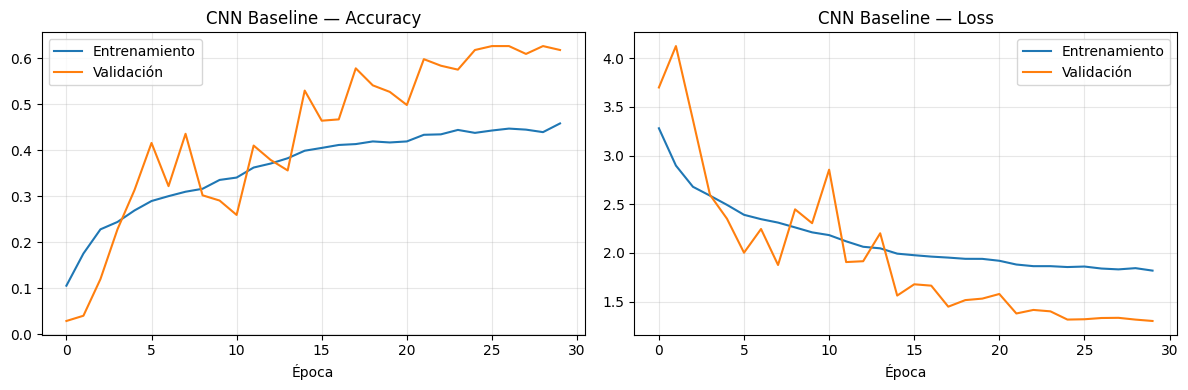

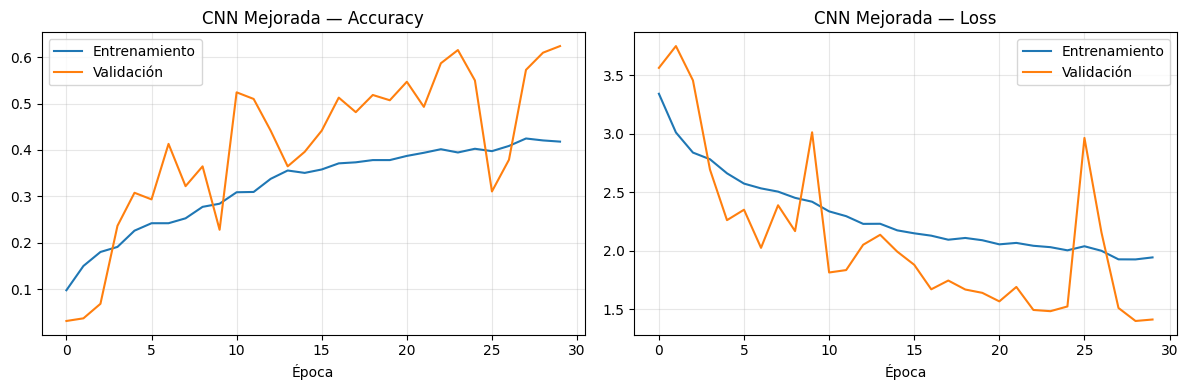

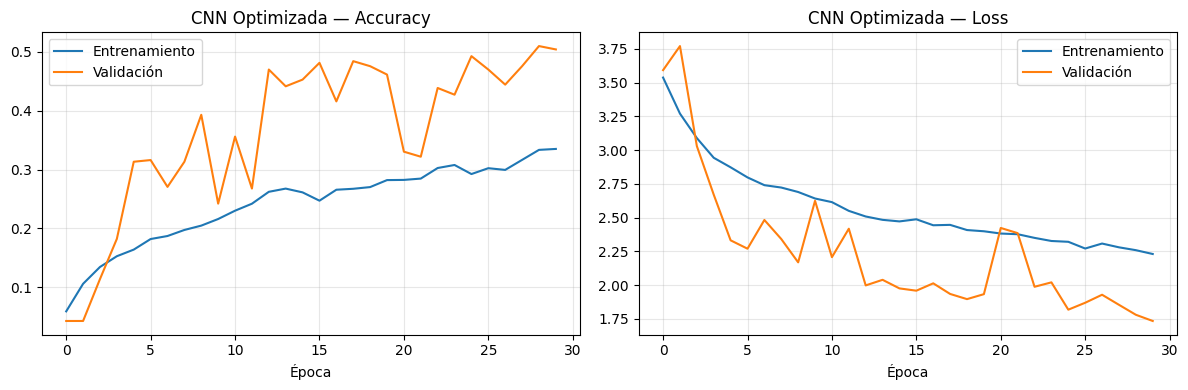

In [14]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history['accuracy'], label='Entrenamiento')
    axes[0].plot(history.history['val_accuracy'], label='Validación')
    axes[0].set_title(f'{title} — Accuracy')
    axes[0].set_xlabel('Época'); axes[0].legend(); axes[0].grid(alpha=.3)
    axes[1].plot(history.history['loss'], label='Entrenamiento')
    axes[1].plot(history.history['val_loss'], label='Validación')
    axes[1].set_title(f'{title} — Loss')
    axes[1].set_xlabel('Época'); axes[1].legend(); axes[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

for name, hist in [
    ('CNN Baseline', history_baseline),
    ('CNN Mejorada', history_improved),
    ('CNN Optimizada', history_optimized)
]:
    plot_history(hist, name)

### Análisis de curvas de aprendizaje

Completar después de ejecutar los tres entrenamientos:

- **Mejor ajuste:** seleccionar el modelo con mayor `val_accuracy` y menor `val_loss`, considerando ambas métricas.
- **Overfitting:** existe indicio cuando la precisión de entrenamiento sigue aumentando mientras la de validación se estanca o disminuye, y la pérdida de validación aumenta.
- **Decisión:** no elegir únicamente por accuracy; revisar también la diferencia entre entrenamiento y validación y el tamaño del modelo.

## Fase 6. Evaluación completa con el conjunto de prueba

Se selecciona automáticamente el modelo con mayor accuracy de validación. La evaluación final se realiza con `test_ds`, que no intervino en el entrenamiento.

In [15]:
model_histories = {
    'CNN Baseline': (model_baseline, history_baseline, dir_baseline),
    'CNN Mejorada': (model_improved, history_improved, dir_improved),
    'CNN Optimizada': (model_optimized, history_optimized, dir_optimized)
}
best_name = max(
    model_histories,
    key=lambda name: max(model_histories[name][1].history['val_accuracy'])
)
best_model, best_history, best_dir = model_histories[best_name]
print("Modelo seleccionado por validación:", best_name)

# Recuperar el mejor checkpoint guardado para el modelo seleccionado.
best_checkpoint = os.path.join(best_dir, 'checkpoints', 'best_model.keras')
if os.path.isfile(best_checkpoint):
    best_model = tf.keras.models.load_model(best_checkpoint)

Modelo seleccionado por validación: CNN Baseline


In [16]:
test_loss, test_accuracy, test_topk = best_model.evaluate(test_ds, verbose=1)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")
print(f"Top-k accuracy: {test_topk:.4f}")

y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true, y_pred, labels=np.arange(NUM_CLASSES),
    target_names=class_names, digits=4, zero_division=0
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 766ms/step - accuracy: 0.6240 - loss: 1.3205 - top_k_accuracy: 0.8607
Test accuracy: 0.6240
Test loss: 1.3205
Top-k accuracy: 0.8607
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step
               precision    recall  f1-score   support

        apple     1.0000    0.3000    0.4615        10
       banana     0.8571    0.6667    0.7500         9
     beetroot     0.5000    0.6000    0.5455        10
  bell pepper     0.6667    0.2000    0.3077        10
      cabbage     0.6667    0.6000    0.6316        10
     capsicum     0.3846    0.5000    0.4348        10
       carrot     0.7692    1.0000    0.8696        10
  cauliflower     0.7500    0.6000    0.6667        10
chilli pepper     0.3636    0.4000    0.3810        10
         corn     0.3333    0.1000    0.1538        10
     cucumber     0.3333    0.4000    0.3636        10
     eggplant     0.7000    0.7000    0.7000        10
       garlic     0.7692    1.0000    0.8696        10
       ginger     0.5833 

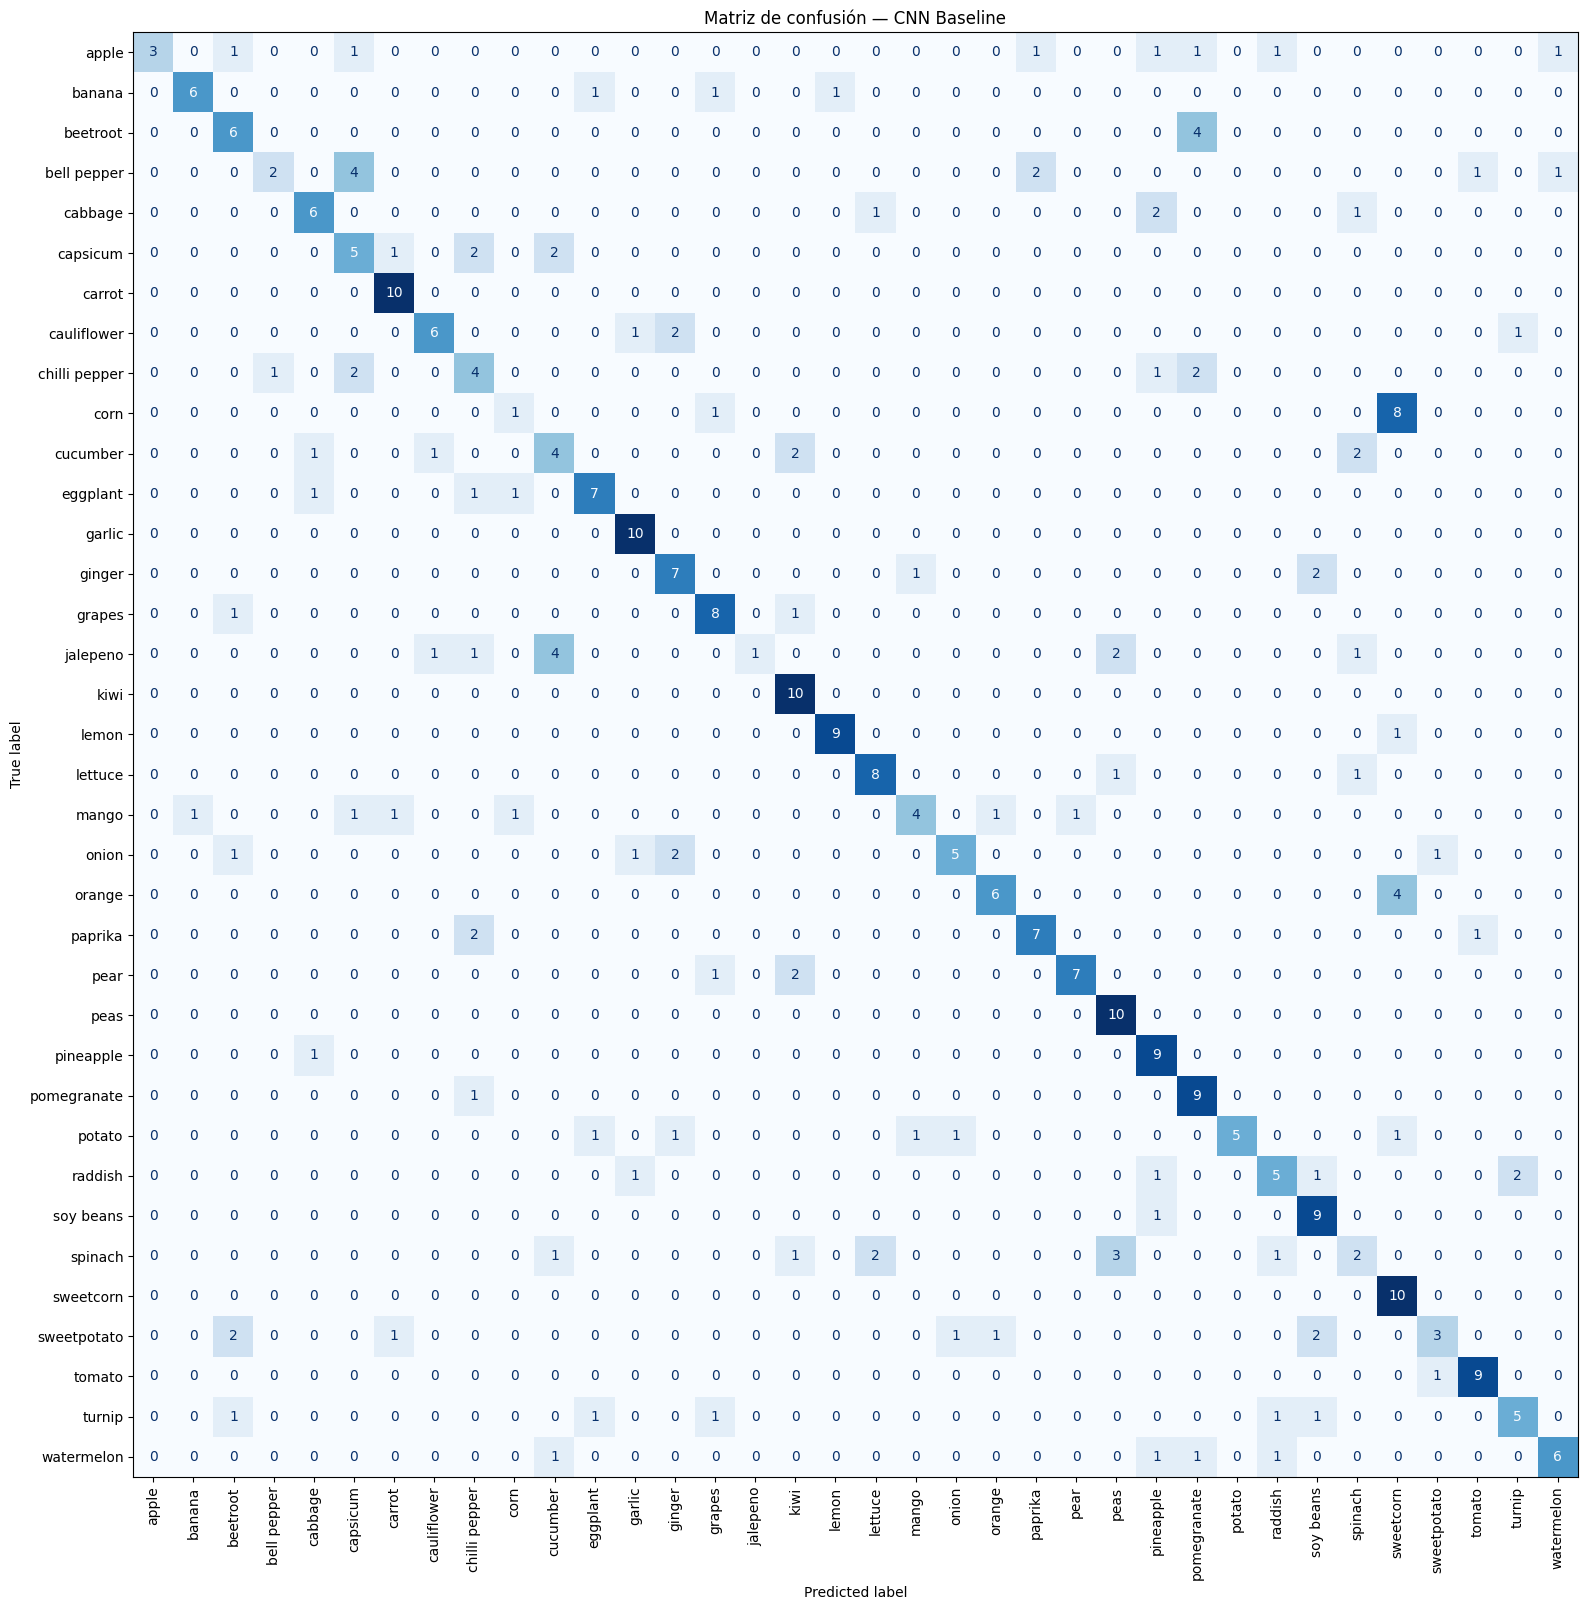

In [17]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
fig_size = max(10, min(22, NUM_CLASSES * 0.45))
fig, ax = plt.subplots(figsize=(fig_size, fig_size))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=90, colorbar=False, values_format='d')
plt.title(f'Matriz de confusión — {best_name}')
plt.tight_layout()
plt.show()

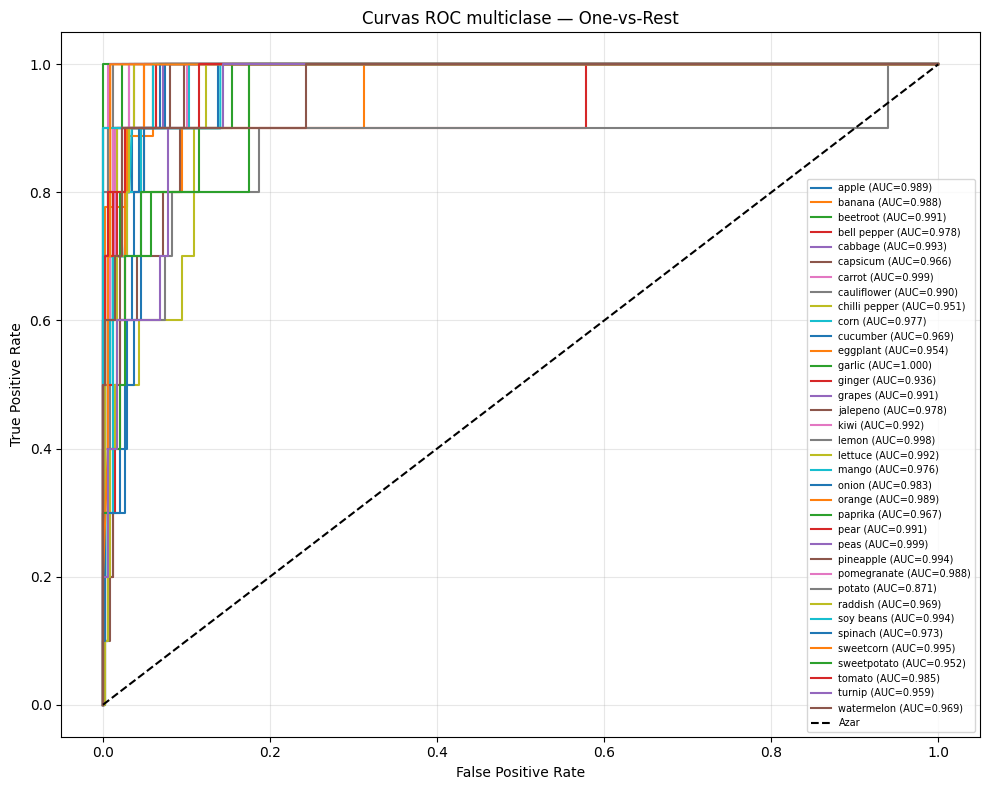

Macro AUC (clases evaluables): 0.9773949252841325


In [18]:
# ROC multiclase OvR. Se omiten clases sin positivos o sin negativos en el test.
y_true_bin = label_binarize(y_true, classes=np.arange(NUM_CLASSES))
valid_classes = [
    i for i in range(NUM_CLASSES)
    if len(np.unique(y_true_bin[:, i])) == 2
]
roc_values = []
plt.figure(figsize=(10, 8))
for i in valid_classes:
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    class_auc = auc(fpr, tpr)
    roc_values.append(class_auc)
    plt.plot(fpr, tpr, label=f'{class_names[i]} (AUC={class_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Curvas ROC multiclase — One-vs-Rest')
plt.legend(fontsize=7, loc='lower right')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

macro_auc = float(np.mean(roc_values)) if roc_values else float('nan')
print("Macro AUC (clases evaluables):", macro_auc)

## Fase 7. Análisis de errores

In [19]:
# Pares de clases que más se confunden (excluyendo la diagonal).
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)
error_pairs = []
for real_idx, pred_idx in zip(*np.where(cm_errors > 0)):
    error_pairs.append({
        'Clase real': class_names[real_idx],
        'Clase predicha': class_names[pred_idx],
        'Cantidad': int(cm_errors[real_idx, pred_idx])
    })
errors_df = pd.DataFrame(error_pairs)
if not errors_df.empty:
    errors_df = errors_df.sort_values('Cantidad', ascending=False).head(10)
    display(errors_df)
else:
    print("No se registraron confusiones entre clases.")

,Clase real,Clase predicha,Cantidad
29,corn,sweetcorn,8
10,beetroot,pomegranate,4
11,bell pepper,capsicum,4
43,jalepeno,cucumber,4
59,orange,sweetcorn,4
79,spinach,peas,3
19,capsicum,chilli pepper,2
12,bell pepper,paprika,2
27,chilli pepper,pomegranate,2
20,capsicum,cucumber,2


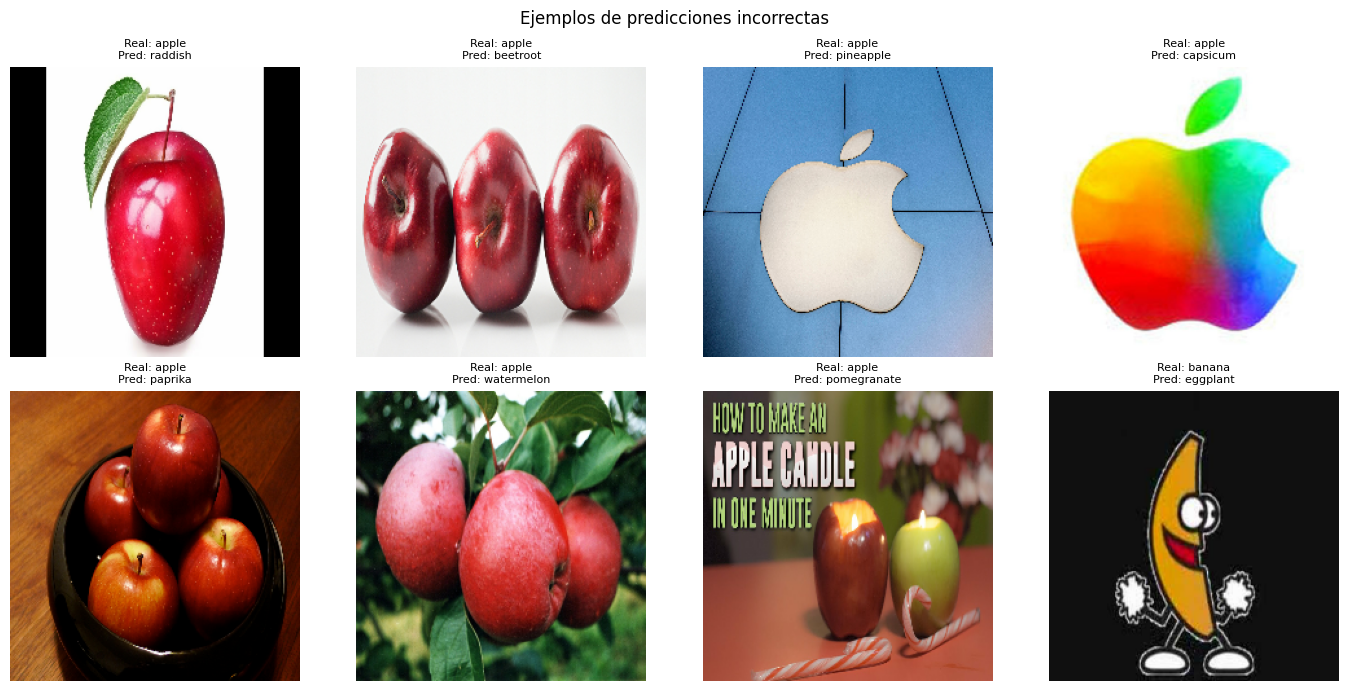

In [20]:
# Visualizar algunas predicciones incorrectas para inspeccionar los errores.
wrong_indices = np.where(y_true != y_pred)[0]
if len(wrong_indices):
    all_test_images = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
    n = min(8, len(wrong_indices))
    chosen = wrong_indices[:n]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, idx in zip(axes.flat, chosen):
        ax.imshow(np.clip(all_test_images[idx], 0, 1))
        ax.set_title(f"Real: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=8)
        ax.axis('off')
    for ax in axes.flat[n:]:
        ax.axis('off')
    plt.suptitle('Ejemplos de predicciones incorrectas')
    plt.tight_layout(); plt.show()
else:
    print("El modelo no presentó errores en el conjunto de prueba.")

### Tabla de mejoras basada en los errores observados

Completar con los nombres que aparezcan en la tabla de confusiones después de ejecutar:

| Hallazgo observado | Acción correctiva propuesta |
|---|---|
| Dos categorías visualmente similares se confunden | Incorporar más imágenes variadas de esas categorías y revisar su calidad/etiquetado. |
| Una clase presenta bajo recall | Aumentar ejemplos de esa clase o aplicar ponderación de clases durante el entrenamiento. |
| Errores por iluminación, fondo o ángulo | Aplicar aumento de datos moderado y recopilar imágenes en condiciones variadas. |

No afirmar que una clase concreta presenta estos problemas hasta comprobarlo en los resultados.

## Fase 8. Comparación sistemática de modelos

In [21]:
comparison_rows = []
for name, (m, hist, exp_dir) in model_histories.items():
    best_epoch = int(np.argmax(hist.history['val_accuracy'])) + 1
    params = m.count_params()
    comparison_rows.append({
        'Modelo': name,
        'Mejor val_accuracy': max(hist.history['val_accuracy']),
        'Menor val_loss': min(hist.history['val_loss']),
        'Épocas ejecutadas': len(hist.history['loss']),
        'Parámetros': params,
        'Tamaño estimado FP32 (MB)': params * 4 / (1024**2),
        'Mejor época': best_epoch
    })
comparison_df = pd.DataFrame(comparison_rows).sort_values('Mejor val_accuracy', ascending=False)
display(comparison_df.round(4))

,Modelo,Mejor val_accuracy,Menor val_loss,Épocas ejecutadas,Parámetros,Tamaño estimado FP32 (MB),Mejor época
0,CNN Baseline,0.6268,1.3013,30,115076,0.4390,26
1,CNN Mejorada,0.6239,1.4016,30,329860,1.2583,30
2,CNN Optimizada,0.5100,1.7353,30,335812,1.2810,29


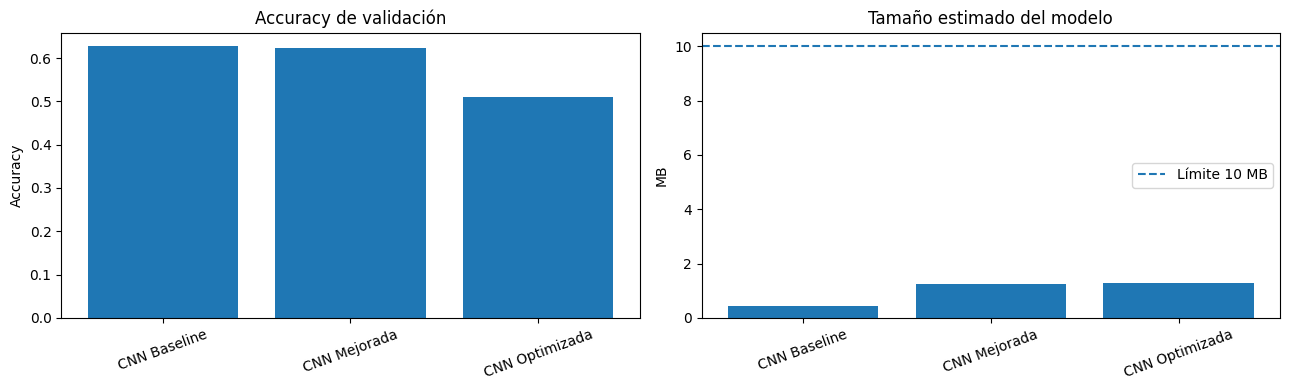

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(comparison_df['Modelo'], comparison_df['Mejor val_accuracy'])
axes[0].set_title('Accuracy de validación')
axes[0].set_ylabel('Accuracy')
axes[0].tick_params(axis='x', rotation=20)
axes[1].bar(comparison_df['Modelo'], comparison_df['Tamaño estimado FP32 (MB)'])
axes[1].axhline(10, linestyle='--', label='Límite 10 MB')
axes[1].set_title('Tamaño estimado del modelo')
axes[1].set_ylabel('MB')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend()
plt.tight_layout(); plt.show()

### Pregunta de producción: modelo menor a 10 MB

El tamaño estimado en FP32 se calcula como `número de parámetros × 4 bytes`. Para producción móvil se debe comprobar el tamaño real del archivo `.tflite`, preferiblemente después de cuantización. Se seleccionará un modelo que cumpla el límite de 10 MB y que mantenga un rendimiento aceptable en validación y prueba. Si ninguno cumple, se deberá cuantizar o reducir la arquitectura.

## Fases 9, 10 y 11. Versionado, logging y documentación

In [23]:
# Registrar metadatos reproducibles del modelo elegido.
os.makedirs('models/production', exist_ok=True)
keras_path = 'models/production/comidas_verduras_best.keras'
best_model.save(keras_path)

metadata = {
    'version': '1.0',
    'created_at': datetime.datetime.now().isoformat(),
    'project': 'Reconocimiento de comidas y verduras mediante CNN',
    'selected_model': best_name,
    'architecture': best_model.name,
    'input_shape': list(best_model.input_shape[1:]),
    'number_of_classes': NUM_CLASSES,
    'class_names': class_names,
    'parameters': int(best_model.count_params()),
    'estimated_fp32_size_mb': best_model.count_params() * 4 / (1024**2),
    'test_accuracy': float(test_accuracy),
    'test_loss': float(test_loss),
    'macro_auc': macro_auc,
    'tensorflow_version': tf.__version__,
    'python_version': platform.python_version(),
    'gpu': str(tf.config.list_physical_devices('GPU'))
}
with open('models/production/metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print(json.dumps(metadata, indent=2, ensure_ascii=False))

{
  "version": "1.0",
  "created_at": "2026-11-11T03:39:57.551013",
  "project": "Reconocimiento de comidas y verduras mediante CNN",
  "selected_model": "CNN Baseline",
  "architecture": "cnn_baseline",
  "input_shape": [
    224,
    224,
    3
  ],
  "number_of_classes": 36,
  "class_names": [
    "apple",
    "banana",
    "beetroot",
    "bell pepper",
    "cabbage",
    "capsicum",
    "carrot",
    "cauliflower",
    "chilli pepper",
    "corn",
    "cucumber",
    "eggplant",
    "garlic",
    "ginger",
    "grapes",
    "jalepeno",
    "kiwi",
    "lemon",
    "lettuce",
    "mango",
    "onion",
    "orange",
    "paprika",
    "pear",
    "peas",
    "pineapple",
    "pomegranate",
    "potato",
    "raddish",
    "soy beans",
    "spinach",
    "sweetcorn",
    "sweetpotato",
    "tomato",
    "turnip",
    "watermelon"
  ],
  "parameters": 115076,
  "estimated_fp32_size_mb": 0.4389801025390625,
  "test_accuracy": 0.6239554286003113,
  "test_loss": 1.3204785585403442,
  "ma

In [24]:
# Verificar que el modelo guardado se pueda volver a cargar.
reloaded_model = tf.keras.models.load_model(keras_path)
reload_loss, reload_accuracy, reload_topk = reloaded_model.evaluate(test_ds, verbose=0)
print(f"Modelo recargado correctamente. Test accuracy: {reload_accuracy:.4f}")

Modelo recargado correctamente. Test accuracy: 0.6240


## Fase 12. Despliegue y conversión a TensorFlow Lite

In [25]:
def convert_to_tflite(model_path, output_path, quantize=False):
    converter = tf.lite.TFLiteConverter.from_keras_model(
        tf.keras.models.load_model(model_path)
    )
    if quantize:
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    tflite_bytes = converter.convert()
    with open(output_path, 'wb') as f:
        f.write(tflite_bytes)
    size_mb = os.path.getsize(output_path) / (1024**2)
    print(f"Archivo: {output_path} | Tamaño real: {size_mb:.2f} MB")
    return size_mb

tflite_path = 'models/production/comidas_verduras.tflite'
tflite_quant_path = 'models/production/comidas_verduras_float16.tflite'

size_tflite = convert_to_tflite(keras_path, tflite_path, quantize=False)
size_tflite_fp16 = convert_to_tflite(keras_path, tflite_quant_path, quantize=True)
print("¿Cuantizado cumple <10 MB?:", size_tflite_fp16 < 10)

Saved artifact at '/tmp/tmpnggcv0dj'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 36), dtype=tf.float32, name=None)
Captures:
  138786451339600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451340944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451341136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451340176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451339408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451340368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451340752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451329808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451340560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786451339984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138786450784

In [26]:
# Función de predicción para una imagen externa.
def predict_image(image_path, model_path=keras_path, class_names=class_names):
    model = tf.keras.models.load_model(model_path)
    image = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    array = tf.keras.utils.img_to_array(image).astype('float32') / 255.0
    probabilities = model.predict(np.expand_dims(array, axis=0), verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:min(3, len(class_names))]

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f"Predicción: {class_names[top_indices[0]]} ({probabilities[top_indices[0]]:.1%})")
    plt.show()

    print("Top predicciones:")
    for idx in top_indices:
        print(f"{class_names[idx]}: {probabilities[idx]:.2%}")
    return class_names[top_indices[0]], float(probabilities[top_indices[0]])

# Ejemplo:
# predict_image('/content/mi_imagen.jpg')

## Reporte técnico breve

**Resumen ejecutivo:** Se desarrolló un clasificador multiclase de imágenes de comidas y verduras mediante redes neuronales convolucionales. Se compararon tres arquitecturas y se seleccionó el modelo con mejor desempeño de validación.

**Dataset:** Completar con la cantidad de imágenes por subconjunto y el número de clases que aparecen en la tabla EDA.

**Resultados principales:** Registrar los valores reales de accuracy, loss, Macro AUC y Macro F1 obtenidos al ejecutar el notebook. No inventar métricas antes de ejecutar.

**Análisis de errores:** Describir los pares de categorías que más se confundieron y relacionarlos con las imágenes mostradas en la fase 7.

**Conclusiones y trabajo futuro:** Indicar si el modelo supera el baseline, si existe overfitting y si el archivo TensorFlow Lite cumple el límite de tamaño. Como trabajo futuro, ampliar clases con pocos ejemplos, mejorar la diversidad de imágenes y evaluar el modelo con fotografías tomadas fuera del dataset.

## Checklist de entrega

- [ ] Fase 1: definición del problema.
- [ ] Fase 2: dataset y EDA.
- [ ] Fase 3: preprocesamiento y data augmentation.
- [ ] Fase 4: tres arquitecturas CNN.
- [ ] Fase 5: entrenamiento con cinco callbacks.
- [ ] Fase 6: evaluación, classification report, matriz de confusión y ROC.
- [ ] Fase 7: análisis de errores.
- [ ] Fase 8: comparación de modelos y criterio de producción.
- [ ] Fase 9: versionado y metadatos.
- [ ] Fase 10: logging CSV y TensorBoard.
- [ ] Fase 11: documentación técnica.
- [ ] Fase 12: exportación y conversión TFLite.

**Nota:** las métricas, gráficas y hallazgos dependen de ejecutar el notebook con el dataset original. El archivo se entrega con el código preparado, pero no se deben presentar resultados numéricos sin haberlo ejecutado.